In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import load_sample_image, load_digits
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)

# ---- Tải tệp dữ liệu lên (bỏ qua nếu tệp đã có trong data/) ----
CAN_CO = ["khach_hang.csv", "hai_vang_trang.csv"]
thieu = [t for t in CAN_CO if not os.path.exists(f"data/{t}")]
if thieu:
    try:
        from google.colab import files
        print("Hay chon cac tep CSV:", thieu)
        for ten, noi_dung in files.upload().items():
            with open(f"data/{os.path.basename(ten)}", "wb") as f:
                f.write(noi_dung)
    except ImportError:
        print("Khong chay tren Colab: hay tu dat cac tep vao thu muc data/")

con_thieu = [t for t in CAN_CO if not os.path.exists(f"data/{t}")]
print("Cac tep trong data/:", os.listdir("data"))
if con_thieu:
    print("CHUA CO:", con_thieu, "-> cac muc dung tep nay se bao loi cho den khi tai len.")

MAU = ["#08306b", "#cb181d", "#1b9e9e", "#e6770a", "#6a3d9a", "#7f7f7f", "#b8860b", "#2ca02c", "#e377c2", "#17becf"]

Hay chon cac tep CSV: ['khach_hang.csv', 'hai_vang_trang.csv']


Saving hai_vang_trang.csv to hai_vang_trang.csv
Saving khach_hang.csv to khach_hang.csv
Cac tep trong data/: ['hai_vang_trang.csv', 'khach_hang.csv']


## 2.

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


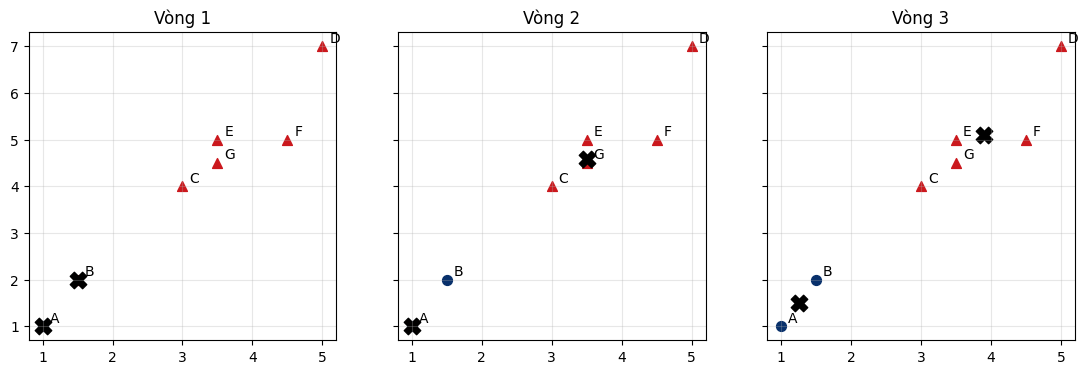

In [2]:
P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]
lich_su = []   # để vẽ hình


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        lich_su.append((tam.copy(), nhan.copy()))
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0) for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


tam, nhan = k_means(P, P[[0, 1]].copy())
print()

inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

fig, axs = plt.subplots(1, len(lich_su), figsize=(4.5 * len(lich_su), 4), sharey=True)
for v, (ax, (t, nh)) in enumerate(zip(np.atleast_1d(axs), lich_su), 1):
    for k in range(2):
        ax.scatter(P[nh == k, 0], P[nh == k, 1], c=MAU[k], marker="o^"[k], s=50)
    ax.scatter(t[:, 0], t[:, 1], c="k", marker="X", s=140)
    for i, ten in enumerate(TEN):
        ax.annotate(ten, P[i], textcoords="offset points", xytext=(5, 3))
    ax.set_title(f"Vòng {v}"); ax.grid(alpha=.3)
plt.show()

## 3.

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


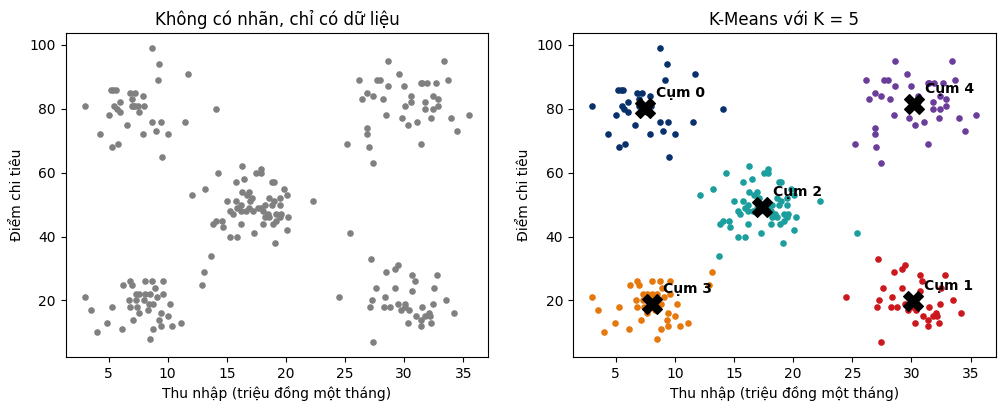

In [3]:
df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0], "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].scatter(X["thu_nhap"], X["diem_chi_tieu"], c="gray", s=14)
axs[0].set_title("Không có nhãn, chỉ có dữ liệu")
for k in range(5):
    m = df["cum"] == k
    axs[1].scatter(df.loc[m, "thu_nhap"], df.loc[m, "diem_chi_tieu"], c=MAU[k], s=14)
axs[1].scatter(tam["thu_nhap"], tam["diem_chi_tieu"], c="k", marker="X", s=200)
for k, r in tam.iterrows():
    axs[1].annotate(f"Cụm {k}", (r["thu_nhap"], r["diem_chi_tieu"]), textcoords="offset points", xytext=(8, 8), weight="bold")
axs[1].set_title("K-Means với K = 5")
for ax in axs:
    ax.set_xlabel("Thu nhập (triệu đồng một tháng)"); ax.set_ylabel("Điểm chi tiêu")
plt.show()

## 4.

 K  inertia  giam so voi K-1  silhouette
  1    420.0                            
  2    250.4           169.6       0.430
  3    152.5            97.9       0.522
  4     73.8            78.8       0.626
  5     23.0            50.7       0.723
  6     20.9             2.1       0.651
  7     19.0             1.9       0.541
  8     17.4             1.6       0.454
  9     15.9             1.5       0.471
 10     14.4             1.4       0.425


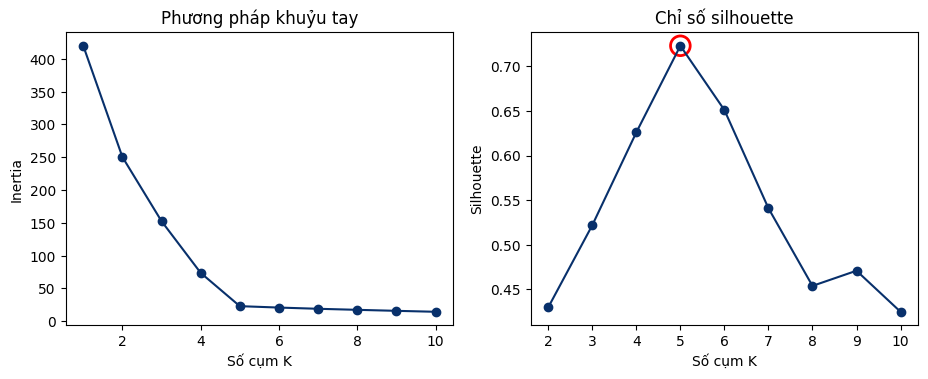

K co silhouette cao nhat: 5


In [4]:
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K  inertia  giam so voi K-1  silhouette")
truoc = None
ds_k, ds_in, ds_sil = [], [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d} {km.inertia_:8.1f} {giam:>15s} {sil:>11s}")
    truoc = km.inertia_
    ds_k.append(k); ds_in.append(km.inertia_); ds_sil.append(np.nan if k == 1 else float(sil))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(ds_k, ds_in, "o-", c=MAU[0]); axs[0].set_title("Phương pháp khuỷu tay")
axs[0].set_xlabel("Số cụm K"); axs[0].set_ylabel("Inertia")
axs[1].plot(ds_k, ds_sil, "o-", c=MAU[0]); axs[1].set_title("Chỉ số silhouette")
axs[1].set_xlabel("Số cụm K"); axs[1].set_ylabel("Silhouette")
k_tot = ds_k[int(np.nanargmax(ds_sil))]
axs[1].scatter([k_tot], [np.nanmax(ds_sil)], s=200, facecolors="none", edgecolors="red", linewidths=2)
plt.show()
print("K co silhouette cao nhat:", k_tot)

## 5.

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


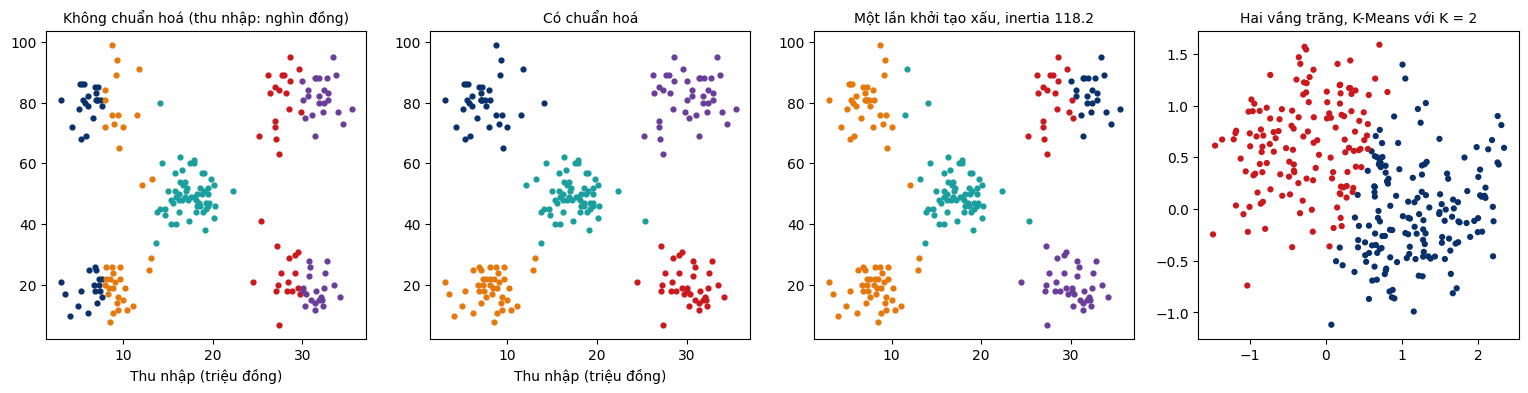

In [5]:
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan_tr = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan_tr == tr["nhan"]).mean()
print(f"Bay 3: hai vang trang, ty le khop nhan that {max(khop, 1 - khop):.4f}")

# Hình minh hoạ
fig, axs = plt.subplots(1, 4, figsize=(19, 4))
for ax, (nh, t) in zip(axs[:2], [(km_tho.labels_, "Không chuẩn hoá (thu nhập: nghìn đồng)"), (tot.labels_, "Có chuẩn hoá")]):
    for k in range(5):
        ax.scatter(X["thu_nhap"][nh == k], X["diem_chi_tieu"][nh == k], c=MAU[k], s=12)
    ax.set_title(t, fontsize=10); ax.set_xlabel("Thu nhập (triệu đồng)")
km_xau = KMeans(n_clusters=5, init="random", n_init=1, random_state=int(np.argmax([KMeans(n_clusters=5, init="random", n_init=1, random_state=r).fit(Xs).inertia_ for r in range(20)]))).fit(Xs)
for k in range(5):
    axs[2].scatter(X["thu_nhap"][km_xau.labels_ == k], X["diem_chi_tieu"][km_xau.labels_ == k], c=MAU[k], s=12)
axs[2].set_title(f"Một lần khởi tạo xấu, inertia {km_xau.inertia_:.1f}", fontsize=10)
axs[3].scatter(tr["x1"], tr["x2"], c=[MAU[i] for i in nhan_tr], s=12)
axs[3].set_title("Hai vầng trăng, K-Means với K = 2", fontsize=10)
plt.show()

## 6.

Anh 427 x 640, co 273280 diem anh, 96615 mau

  K  so bit moi diem   nho hon   sai lech trung binh
  4        2            12.0 lan      17.41 muc sang
 16        4             6.0 lan       7.97 muc sang
 64        6             4.0 lan       4.54 muc sang


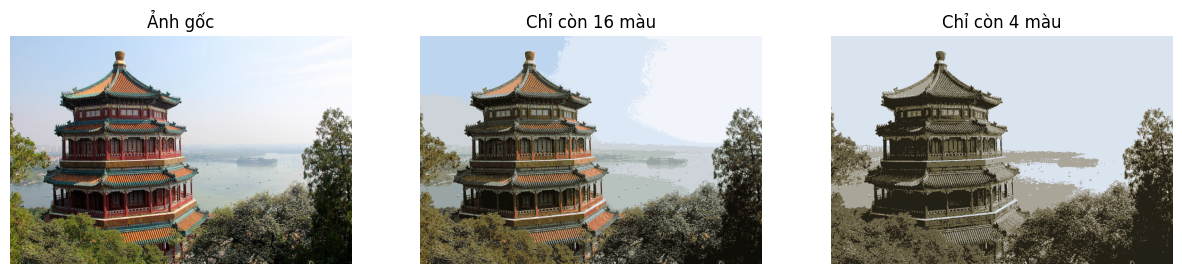

In [6]:
anh = load_sample_image("china.jpg")
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

anh_nen = {}
print("  K  so bit moi diem   nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    anh_nen[k] = moi.reshape(cao, rong, 3)
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d}        {bit}            {24 / bit:4.1f} lan"
          f"      {sai:5.2f} muc sang")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, t) in zip(axs, [(anh, "Ảnh gốc"), (anh_nen[16], "Chỉ còn 16 màu"), (anh_nen[4], "Chỉ còn 4 màu")]):
    ax.imshow(a); ax.set_title(t); ax.axis("off")
plt.show()

## 7. Bài tập

Silhouette trung binh tu tinh : 0.7227
silhouette_score cua sklearn  : 0.7227

Khach co s nho nhat: so 113, a = 0.918, b = 0.945, s = 0.029
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
cum               2.0


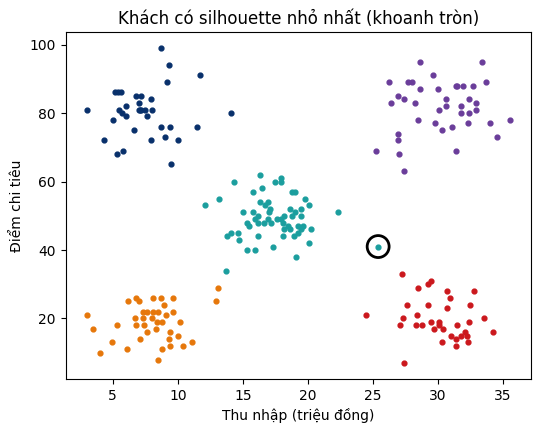

In [7]:
def silhouette_mot_diem(X, nhan, i):
    """Tinh a, b, s cua diem thu i, chi dung numpy."""
    X = np.asarray(X)
    kc = np.sqrt(((X - X[i]) ** 2).sum(axis=1))         # khoang cach tu diem i toi moi diem
    cung = (nhan == nhan[i]); cung[i] = False           # cung cum, bo chinh no
    a = kc[cung].mean() if cung.any() else 0.0
    b = min(kc[nhan == c].mean() for c in np.unique(nhan) if c != nhan[i])
    s = (b - a) / max(a, b) if cung.any() else 0.0
    return a, b, s


Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
km5 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
nhan5 = km5.labels_

kq = np.array([silhouette_mot_diem(Xs, nhan5, i) for i in range(len(Xs))])
print(f"Silhouette trung binh tu tinh : {kq[:, 2].mean():.4f}")
print(f"silhouette_score cua sklearn  : {silhouette_score(Xs, nhan5):.4f}")

i_min = int(kq[:, 2].argmin())
print(f"\nKhach co s nho nhat: so {i_min}, a = {kq[i_min, 0]:.3f}, b = {kq[i_min, 1]:.3f}, s = {kq[i_min, 2]:.3f}")
print(df.loc[i_min, ["tuoi", "thu_nhap", "diem_chi_tieu", "cum"]].to_string())

fig, ax = plt.subplots(figsize=(6, 4.5))
for k in range(5):
    m = nhan5 == k
    ax.scatter(df["thu_nhap"][m], df["diem_chi_tieu"][m], c=MAU[k], s=12)
ax.scatter(df.loc[i_min, "thu_nhap"], df.loc[i_min, "diem_chi_tieu"], s=250, facecolors="none", edgecolors="k", linewidths=2)
ax.set_xlabel("Thu nhập (triệu đồng)"); ax.set_ylabel("Điểm chi tiêu"); ax.set_title("Khách có silhouette nhỏ nhất (khoanh tròn)")
plt.show()

In [8]:
X3 = df[["tuoi", "thu_nhap", "diem_chi_tieu"]]
sc3 = StandardScaler().fit(X3)
X3s = sc3.transform(X3)

print(" K  silhouette")
ds = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X3s)
    ds[k] = silhouette_score(X3s, km.labels_)
    print(f" {k:2d}   {ds[k]:.3f}")
k3 = max(ds, key=ds.get)
print("\nK tot nhat voi 3 cot:", k3)

km3 = KMeans(n_clusters=k3, n_init=10, random_state=0).fit(X3s)
tam3 = pd.DataFrame(sc3.inverse_transform(km3.cluster_centers_), columns=["tuoi", "thu_nhap", "diem_chi_tieu"])
tam3["so_khach"] = np.bincount(km3.labels_)
print("\nTam cum (don vi goc), 3 cot:")
print(tam3.round(1).sort_values("thu_nhap").to_string())
print("\nTam cum muc 3 (2 cot, K = 5) de so sanh:")
print(tam.round(1).sort_values("thu_nhap").to_string())

 K  silhouette
  2   0.373
  3   0.422
  4   0.456
  5   0.481
  6   0.476
  7   0.463
  8   0.460
  9   0.462
 10   0.457

K tot nhat voi 3 cot: 5

Tam cum (don vi goc), 3 cot:
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.9       8.0           18.9        40
1  25.1       8.5           77.6        39
4  41.6      17.6           49.2        57
2  42.9      30.1           20.0        35
3  32.1      30.3           82.0        39

Tam cum muc 3 (2 cot, K = 5) de so sanh:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
3       8.0           18.9        40     44.9
2      17.4           49.3        60     40.4
1      30.1           20.0        35     42.9
4      30.2           81.5        40     32.6


In [9]:
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
tham_chieu = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs).inertia_
print(f"Inertia tham chieu (n_init=10, k-means++): {tham_chieu:.1f}")

for cach in ["random", "k-means++"]:
    in_ = np.array([KMeans(n_clusters=5, init=cach, n_init=1, random_state=rs).fit(Xs).inertia_ for rs in range(50)])
    dat = int((np.abs(in_ - tham_chieu) < 0.05).sum())
    print(f"init = {cach:10s}: dat inertia tot {dat:2d}/50 lan, te nhat {in_.max():.1f}")

Inertia tham chieu (n_init=10, k-means++): 23.0
init = random    : dat inertia tot 30/50 lan, te nhat 204.0
init = k-means++ : dat inertia tot 50/50 lan, te nhat 23.0


In [10]:
anh01 = anh / 255.0
km16 = KMeans(n_clusters=16, n_init=4, random_state=0).fit(mau)
anh_16 = km16.cluster_centers_[km16.predict(diem)].reshape(cao, rong, 3)

plt.imsave("anh_goc.png", anh01)
plt.imsave("anh_16_mau.png", anh_16)
kt_goc, kt_16 = os.path.getsize("anh_goc.png"), os.path.getsize("anh_16_mau.png")
print(f"anh_goc.png   : {kt_goc / 1024:8.1f} KB")
print(f"anh_16_mau.png: {kt_16 / 1024:8.1f} KB  (nho hon {kt_goc / kt_16:.2f} lan)")

anh_goc.png   :    538.4 KB
anh_16_mau.png:    151.8 KB  (nho hon 3.55 lan)


Saving OIP.webp to OIP.webp
Goc: 105.7 KB, 16 mau: 30.6 KB (nho hon 3.45 lan)


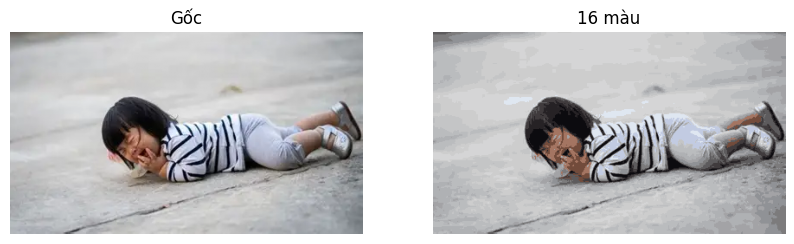

In [11]:
def nen_anh_rieng(duong_dan, k=16):
    a = plt.imread(duong_dan)
    if a.dtype == np.uint8:
        a = a / 255.0
    a = a[..., :3]                                   # bỏ kênh trong suốt nếu có
    h, w, _ = a.shape
    d = a.reshape(-1, 3)
    mau_ = d[np.random.default_rng(0).choice(len(d), min(5000, len(d)), replace=False)]
    km_ = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau_)
    moi_ = km_.cluster_centers_[km_.predict(d)].reshape(h, w, 3)
    plt.imsave("anh_rieng_goc.png", a); plt.imsave("anh_rieng_16_mau.png", moi_)
    g, n = os.path.getsize("anh_rieng_goc.png"), os.path.getsize("anh_rieng_16_mau.png")
    print(f"Goc: {g/1024:.1f} KB, {k} mau: {n/1024:.1f} KB (nho hon {g/n:.2f} lan)")
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    axs[0].imshow(a); axs[0].set_title("Gốc"); axs[1].imshow(moi_); axs[1].set_title(f"{k} màu")
    for ax in axs: ax.axis("off")
    plt.show()

try:
    from google.colab import files
    tai_len = files.upload()
    for ten in tai_len:
        with open(ten, "wb") as f:
            f.write(tai_len[ten])
        nen_anh_rieng(ten)
except ImportError:
    print("Khong phai Colab: goi nen_anh_rieng('duong_dan_anh.png') voi anh cua em.")

K-Means K = 2: khop nhan that 0.7500

 eps  so cum  so diem nhieu (-1)  khop nhan that (bo diem nhieu)
 0.2       1                 40  (khong co 2 cum)
 0.3       1                 10  (khong co 2 cum)
 0.4       1                  3  (khong co 2 cum)


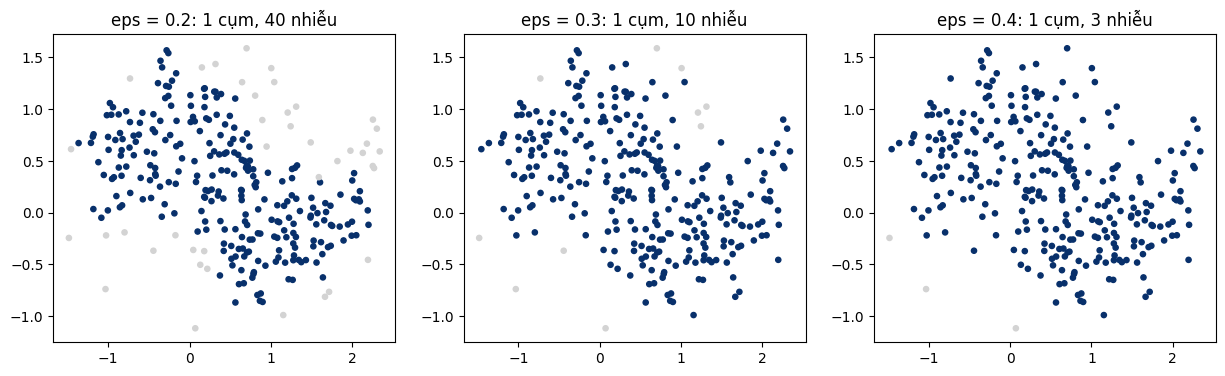

In [12]:
tr = pd.read_csv("data/hai_vang_trang.csv")
Xt = tr[["x1", "x2"]].values
yt = tr["nhan"].values

print(f"K-Means K = 2: khop nhan that {max((nhan_tr == yt).mean(), 1 - (nhan_tr == yt).mean()):.4f}")
print()
print(" eps  so cum  so diem nhieu (-1)  khop nhan that (bo diem nhieu)")
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, e in zip(axs, [0.2, 0.3, 0.4]):
    nh = DBSCAN(eps=e, min_samples=5).fit_predict(Xt)
    so_cum = len(set(nh)) - (1 if -1 in nh else 0)
    nhieu = int((nh == -1).sum())
    ok = nh != -1
    if so_cum == 2 and ok.any():
        kh = (nh[ok] == yt[ok]).mean(); kh = max(kh, 1 - kh); kh_txt = f"{kh:.4f}"
    else:
        kh_txt = "(khong co 2 cum)"
    print(f" {e:.1f}  {so_cum:6d}  {nhieu:17d}  {kh_txt}")
    cols = ["lightgray" if l == -1 else MAU[l % 10] for l in nh]
    ax.scatter(Xt[:, 0], Xt[:, 1], c=cols, s=14); ax.set_title(f"eps = {e}: {so_cum} cụm, {nhieu} nhiễu")
plt.show()

**Nhận xét:** `eps` là bán kính "láng giềng". Nếu `eps` quá nhỏ, nhiều điểm không đủ hàng xóm nên bị gán nhiễu và vầng trăng vỡ thành nhiều cụm nhỏ. Nếu `eps` quá lớn, hai vầng trăng dính vào nhau thành một cụm. Hãy đọc bảng trên để thấy giá trị nào cho đúng hai cụm. DBSCAN không giả định cụm hình cầu nên **có thể** bám theo hình cong và tách tốt hơn K-Means (chỉ khoảng 0.75), nhưng rất nhạy với `eps`; bộ dữ liệu nhiễu nhiều thì cũng có thể không có `eps` nào tách hoàn hảo.

In [13]:
Xd, yd = load_digits(return_X_y=True)
km10 = KMeans(n_clusters=10, n_init=10, random_state=0).fit(Xd)      # không dùng nhãn
bang = pd.crosstab(pd.Series(yd, name="chu so that"), pd.Series(km10.labels_, name="cum"))
print(bang.to_string())

print("\nMoi chu so: cum chua nhieu anh nhat va ty le")
for c in range(10):
    hang = bang.loc[c]
    print(f"  chu so {c}: cum {hang.idxmax()}, {hang.max()}/{hang.sum()} anh ({hang.max()/hang.sum():.0%})")

print("\nMoi cum: cac chu so ben trong")
for k in bang.columns:
    cot = bang[k]
    top = cot[cot > 0.15 * cot.sum()].sort_values(ascending=False)
    print(f"  cum {k}: " + ", ".join(f"{i}({v})" for i, v in top.items()))

cum            0    1    2   3    4    5    6    7    8    9
chu so that                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Moi chu so: cum chua nhieu anh nhat va ty le
  chu so 0: cum 0, 176/178 anh (99%)
  chu so 1: cum 1, 100/182 anh (55%)
  chu so 2: cum 9, 148/177 anh (84%)
  chu so 3: cum 4, 154/183 anh (84%)
  chu so 4: cum 6, 165/181 anh (91%)
  chu so 5: cum 7, 136/182 anh (75%)
